# Trabalho Final de Machine Learning — Predição e Classificação da Qualidade de Vinhos

**Equipe:** Maria Julia, Lorraini Vieira, Gabriel Meuurer e Camilly Zanette

**Dataset:** `group_1_winequality.csv` — dados físico-químicos de vinhos tintos e brancos com nota de qualidade sensorial (0 a 10).

**Objetivo:** construir um pipeline completo de Machine Learning em duas partes:
1. **Regressão** — prever a nota `quality` como valor contínuo;
2. **Classificação** — agrupar as notas em faixas e prever a faixa.

Roteiro do notebook:
0. Configuração e bibliotecas
1. Carregamento e limpeza dos dados
2. Análise exploratória (histogramas, scatter plots, correlação)
3. Pré-processamento (ausentes, outliers, padronização)
4. Parte 1 — Regressão
5. Parte 2 — Classificação
6. Conclusões

## 0. Configuração
Bibliotecas usadas: `pandas`/`numpy` (dados), `matplotlib`/`seaborn` (gráficos),
`scikit-learn` (modelos e métricas) e `imbalanced-learn` (SMOTE para balanceamento).

Se faltar alguma: `pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn`

### Glossário rápido

**Variáveis do vinho** (nomes originais do arquivo → significado):

| Variável | Em português | O que mede |
|---|---|---|
| `fixed acidity` | acidez fixa | ácidos não voláteis (ex.: tartárico), dão "estrutura" ao vinho |
| `volatile acidity` | acidez volátil | ácido acético; em excesso dá gosto de vinagre |
| `citric acid` | ácido cítrico | acrescenta frescor |
| `residual sugar` | açúcar residual | açúcar que sobra após a fermentação (g/L) |
| `chlorides` | cloretos | quantidade de sal |
| `free sulfur dioxide` | SO2 livre | dióxido de enxofre ativo, protege contra oxidação |
| `total sulfur dioxide` | SO2 total | SO2 livre + combinado |
| `density` | densidade | depende do álcool e do açúcar |
| `pH` | pH | acidez geral (menor = mais ácido) |
| `sulphates` | sulfatos | aditivo que atua como conservante |
| `alcohol` | teor alcoólico | % de álcool por volume |
| `type` | tipo | tinto (`red`) ou branco (`white`) |
| `quality` | qualidade | **alvo**: nota sensorial de 0 a 10 |

**Métricas e termos usados:**
- **RMSE** — erro médio "quadrático", na mesma unidade da nota (quanto menor, melhor); pune erros grandes.
- **MAE** — erro médio absoluto: em média, quantos pontos de nota o modelo erra.
- **R²** — fração da variação da nota explicada pelo modelo (0 = não explica nada, 1 = explica tudo).
- **F1-macro** — média do F1 de cada classe com peso igual; boa métrica quando as classes são desbalanceadas.
- **Validação cruzada (CV)** — o treino é dividido em 5 partes; o modelo treina em 4 e é avaliado na 5ª, em rodízio.
- **Winsorização** — limitar valores extremos aos percentis 1% e 99% em vez de apagar as linhas.
- **SMOTE** — cria exemplos sintéticos das classes raras para equilibrar o treino.
- **Data leakage (vazamento)** — quando informação do teste "vaza" para o treino e infla os resultados.

In [1]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, classification_report,
                             f1_score, mean_absolute_error, r2_score, root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

SEED = 42                       # semente fixa -> resultados reprodutíveis
CAMINHO_CSV = "group_1_winequality.csv"         # ajuste se o arquivo estiver em outra pasta

# Nomes em português usados apenas nos gráficos e tabelas de apresentação
# (o código e o modelo continuam usando os nomes originais das colunas).
NOMES_PT = {
    "fixed acidity": "acidez fixa", "volatile acidity": "acidez volátil",
    "citric acid": "ácido cítrico", "residual sugar": "açúcar residual",
    "chlorides": "cloretos", "free sulfur dioxide": "SO2 livre",
    "total sulfur dioxide": "SO2 total", "density": "densidade", "pH": "pH",
    "sulphates": "sulfatos", "alcohol": "teor alcoólico", "quality": "qualidade",
    "type": "tipo", "type_white": "tipo = branco",
}
TIPO_PT = {"red": "Tinto", "white": "Branco"}
CORES_TIPO = {"Tinto": "#8c2d4a", "Branco": "#d9c27a"}

## 1. Carregamento e limpeza dos dados

Antes de qualquer análise, inspecionamos o arquivo bruto. Ao ler o CSV percebemos que
**ele não está limpo**: algumas colunas que deveriam ser numéricas vieram como texto e
vários valores estão em escala errada.

In [2]:
bruto = pd.read_csv(CAMINHO_CSV)
print(bruto.shape)
print(bruto.dtypes)
bruto.describe().T

(6497, 13)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                     str
type                        str
quality                 float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6346.0,7.224070,1.471913,3.80,6.400,7.000,7.700,63.000
volatile acidity,6496.0,28.514717,131.028738,0.08,0.230,0.300,0.420,975.000
citric acid,6496.0,0.321562,0.277260,0.00,0.250,0.310,0.390,19.350
residual sugar,6496.0,5.454618,4.828859,0.60,1.800,3.000,8.100,72.000
chlorides,6496.0,49.887672,40.569811,0.02,34.000,45.000,59.000,1369.000
free sulfur dioxide,6496.0,30.817426,29.442045,1.00,17.000,29.000,41.000,1924.000
total sulfur dioxide,6496.0,116.108605,63.399395,6.00,77.000,118.000,156.000,2430.000
density,6496.0,112.117052,234.952804,0.99,9.953,98.963,99.526,4365.944
pH,6496.0,3.231449,1.057750,2.72,3.110,3.210,3.320,87.480
sulphates,6496.0,0.534009,0.267513,0.22,0.430,0.510,0.600,18.450


In [3]:
# Exemplos de problemas encontrados no arquivo bruto
print("type:", bruto["type"].value_counts(dropna=False).to_dict())
print("quality:", bruto["quality"].value_counts(dropna=False).sort_index().to_dict())
alc = pd.to_numeric(bruto["alcohol"], errors="coerce")
print("alcohol não numérico (amostra):", bruto.loc[alc.isna() & bruto["alcohol"].notna(), "alcohol"].head(5).tolist())
print("chlorides acima de 1 (amostra):", bruto.loc[bruto["chlorides"] > 1, "chlorides"].head(5).tolist())
print("density acima de 1.04 (amostra):", bruto.loc[bruto["density"] > 1.04, "density"].head(5).tolist())
print("linhas duplicadas:", bruto.duplicated().sum())

type: {'white': 4896, 'red': 1599, 'whitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhite': 1, nan: 1}
quality: {3.0: 30, 4.0: 216, 5.0: 2138, 6.0: 2835, 7.0: 1078, 8.0: 193, 9.0: 5, 238.0: 1, nan: 1}
alcohol não numérico (amostra): ['100.333.333.333.333', '100.333.333.333.333', '110.666.666.666.667', '956.666.666.666.667', '135.666.666.666.667']
chlorides acima de 1 (amostra): [76.0, 98.0, 92.0, 75.0, 76.0]
density acima de 1.04 (amostra): [9.978, 9.968, 997.0, 998.0, 9.978]
linhas duplicadas: 1123


### Diagnóstico
O arquivo bruto tem **6.497 linhas e 13 colunas**. Antes de modelar, inspecionamos `dtypes`, `describe()` e amostras de valores, e encontramos problemas típicos de exportação via Excel:

| Problema encontrado | Exemplo no arquivo | Evidência | Efeito se não corrigido |
|---|---|---|---|
| `alcohol` lido como **texto** | `100.333.333.333.333`, `956.666.666.666.667` | coluna com `dtype` texto | modelo não consegue usar a variável |
| **Vírgula decimal perdida** | `chlorides` = 76 (era 0,076); `volatile acidity` = 675; `density` = 9,978 ou 998 | média de `density` = 112 (o esperado é ≈ 0,994) | escala absurda distorce padronização e coeficientes |
| **`type` corrompido** | `whitewhite…white` (repetido) e 1 valor ausente | `value_counts` com categorias extras | `type` viraria dezenas de categorias falsas |
| **`quality` inválida** | um valor **238** e um ausente | máximo da coluna = 238 | o alvo não pode ser imputado |
| **Valores ausentes** | `fixed acidity` com 151 vazios; 1 a 2 em outras colunas | `describe()` com `count` menor | exigem imputação sem vazar o teste |
| **Linhas duplicadas** | 1.123 no arquivo bruto | `duplicated().sum()` | a mesma amostra cairia em treino e teste e **inflaria as métricas** |

**Por que isso importa:** sem a limpeza, qualquer resultado seria enganoso. Um único `quality = 238` e densidades de ordem 1.000 sozinhos já destruiriam a padronização e o R². Por isso a limpeza vem antes de tudo, e os valores que não dá para recuperar viram `NaN` para serem imputados **dentro do pipeline** (só com dados do treino).

**Resultado:** removemos 3 linhas (alvo ou tipo inválidos) e 1.125 duplicadas, ficando com **5.369 vinhos**. Após a correção, as estatísticas ficam coerentes com a literatura (densidade ≈ 0,994; cloretos ≈ 0,057; álcool ≈ 10,5%; nota entre 3 e 9). Valores irrecuperáveis viraram `NaN`: 96 em `density`, 1 em `chlorides` e 1 em `pH` (sobraram 71 em `density` depois de remover duplicadas).

### Estratégia de limpeza
- **Vírgula decimal perdida** (ex.: `chlorides` 76 → 0,076; `density` 9.978 → 0,9978): cada variável
  tem uma faixa plausível (baseada no dataset original da UCI). Valores fora dela são divididos por
  potências de 10 até caírem na faixa; se nunca caem, viram `NaN` e são imputados depois.
- **`alcohol` como texto** (ex.: `100.333.333.333.333` → 10,03): removemos os separadores e
  reposicionamos a vírgula.
- **`type` corrompido** (`whitewhite...`) → `white`; `type` ausente → linha removida.
- **`quality` ausente ou fora de 0–10** → linha removida (o alvo não pode ser imputado).
- **Duplicadas** → removidas, para que a mesma amostra não apareça em treino e teste
  (isso inflaria artificialmente as métricas).
- **Valores ausentes restantes** → imputados pela mediana **dentro do pipeline**, usando apenas
  o conjunto de treino (evita *data leakage*).

In [4]:
FAIXAS = {
    "fixed acidity": (3.5, 16.5), "volatile acidity": (0.05, 1.8), "citric acid": (0.0, 1.7),
    "residual sugar": (0.5, 70.0), "chlorides": (0.005, 0.65), "free sulfur dioxide": (1.0, 300.0),
    "total sulfur dioxide": (5.0, 450.0), "density": (0.985, 1.04), "pH": (2.7, 4.1),
    "sulphates": (0.2, 2.1), "alcohol": (8.0, 15.0),
}
# Valores originais com 3 casas decimais que perderam "0," -> inteiro / 1000
DIVISOR_INTEIROS = {"chlorides": 1000, "volatile acidity": 1000}


def reescalar(valor, minimo, maximo, divisor_inteiro=None):
    """Corrige valores que perderam a vírgula decimal; devolve NaN se irrecuperável."""
    if pd.isna(valor):
        return np.nan
    if minimo <= valor <= maximo:
        return valor
    if divisor_inteiro and float(valor).is_integer():
        v = valor / divisor_inteiro
        return v if minimo <= v <= maximo else np.nan
    v = float(valor)
    for _ in range(6):
        v /= 10
        if minimo <= v <= maximo:
            return v
    return np.nan


def corrigir_alcohol(texto):
    """'100.333.333.333' -> 10.0333 ; '9.39.39.39' -> 9.3 ; '10.5' -> 10.5"""
    if pd.isna(texto):
        return np.nan
    s = str(texto).strip().replace(",", ".")
    try:
        return float(s)
    except ValueError:
        pass
    partes = s.split(".")
    if len(partes) > 2 and len(set(partes[1:-1])) == 1 and len(partes[1]) == 2:
        return float(f"{partes[0]}.{partes[1][0]}")
    digitos = re.sub(r"\D", "", s)
    for k in (1, 2):
        try:
            v = float(digitos[:k] + "." + digitos[k:])
        except ValueError:
            continue
        if FAIXAS["alcohol"][0] <= v <= FAIXAS["alcohol"][1]:
            return v
    return np.nan


def corrigir_tipo(texto):
    if pd.isna(texto):
        return np.nan
    s = str(texto).strip().lower()
    return "white" if s.startswith("white") else "red" if s.startswith("red") else np.nan


df = bruto.copy()
log = {}
df["alcohol"] = df["alcohol"].apply(corrigir_alcohol)
for col, (lo, hi) in FAIXAS.items():
    df[col] = pd.to_numeric(df[col], errors="coerce")
    fora = df[col].notna() & ~df[col].between(lo, hi)
    df[col] = df[col].apply(lambda v: reescalar(v, lo, hi, DIVISOR_INTEIROS.get(col)))
    log[col] = {"fora_da_faixa": int(fora.sum()), "virou_NaN": int((fora & df[col].isna()).sum())}
df["type"] = df["type"].apply(corrigir_tipo)

df["quality"] = pd.to_numeric(df["quality"], errors="coerce")
invalida = df["quality"].isna() | ~df["quality"].between(0, 10) | df["type"].isna()
print("linhas removidas (quality/type inválidos):", int(invalida.sum()))
df = df[~invalida].copy()
df["quality"] = df["quality"].astype(int)

n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("duplicadas removidas:", n_dup)
print("linhas finais:", len(df))
pd.DataFrame(log).T

linhas removidas (quality/type inválidos): 3
duplicadas removidas: 1125
linhas finais: 5369


,fora_da_faixa,virou_NaN
fixed acidity,1,0
volatile acidity,343,0
citric acid,1,0
residual sugar,1,0
chlorides,5766,1
free sulfur dioxide,1,0
total sulfur dioxide,1,0
density,6426,96
pH,1,1
sulphates,1,0


In [5]:
# Conferência: depois da limpeza as estatísticas ficam coerentes com a literatura
print("Valores ausentes restantes (serão imputados no pipeline):")
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T.round(3)

Valores ausentes restantes (serão imputados no pipeline):
fixed acidity           151
volatile acidity          1
citric acid               1
residual sugar            1
chlorides                 2
free sulfur dioxide       1
total sulfur dioxide      1
density                  71
pH                        2
sulphates                 1
alcohol                   1
dtype: int64


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5218.0,7.213,1.316,3.800,6.400,7.000,7.700,15.900
volatile acidity,5368.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric acid,5368.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual sugar,5368.0,5.070,4.517,0.600,1.800,2.700,7.500,65.800
chlorides,5367.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,5368.0,30.137,17.987,1.000,17.000,28.000,41.000,289.000
total sulfur dioxide,5368.0,114.302,56.800,6.000,75.000,116.000,154.000,440.000
density,5298.0,0.994,0.003,0.987,0.992,0.995,0.997,1.039
pH,5367.0,3.225,0.161,2.720,3.110,3.210,3.330,4.010
sulphates,5368.0,0.534,0.151,0.220,0.430,0.510,0.600,2.000


## 2. Análise exploratória (EDA)
### 2.1 Distribuição do alvo `quality`

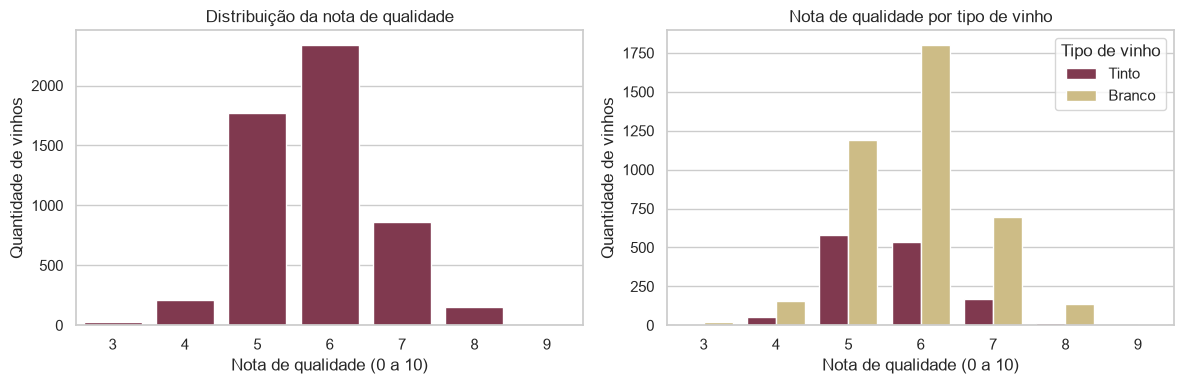

quality
3    0.006
4    0.039
5    0.330
6    0.436
7    0.161
8    0.028
9    0.001
Name: proportion, dtype: float64


In [6]:
# Coluna auxiliar só para os gráficos (rótulos em português); não entra no modelo.
df["tipo_pt"] = df["type"].map(TIPO_PT)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="quality", data=df, ax=ax[0], color="#8c2d4a")
ax[0].set_title("Distribuição da nota de qualidade")
ax[0].set_xlabel("Nota de qualidade (0 a 10)"); ax[0].set_ylabel("Quantidade de vinhos")
sns.countplot(x="quality", hue="tipo_pt", data=df, ax=ax[1], palette=CORES_TIPO)
ax[1].set_title("Nota de qualidade por tipo de vinho")
ax[1].set_xlabel("Nota de qualidade (0 a 10)"); ax[1].set_ylabel("Quantidade de vinhos")
ax[1].legend(title="Tipo de vinho")
plt.tight_layout(); plt.show()
print(df["quality"].value_counts(normalize=True).sort_index().round(3))

**O que o gráfico mostra.** A nota se concentra em **5 (33,0%) e 6 (43,6%)**, com 7 em 16,1%. As pontas são raríssimas: nota 3 = 0,6%, nota 8 = 2,8% e nota 9 = apenas 0,1% (5 vinhos). Os tintos e brancos têm formas parecidas de distribuição, com a maior parte nas notas 5 e 6.

**Por que importa.**
- Quase não existem vinhos "péssimos" ou "excelentes", então o modelo tem **pouquíssimos exemplos para aprender as pontas** da escala.
- Na **regressão**, isso empurra as previsões para o centro (regressão à média).
- Na **classificação**, a classe "baixa" será minoritária, o que exige tratamento de desbalanceamento e uma métrica que não seja a acurácia.

### 2.2 Histogramas das variáveis físico-químicas

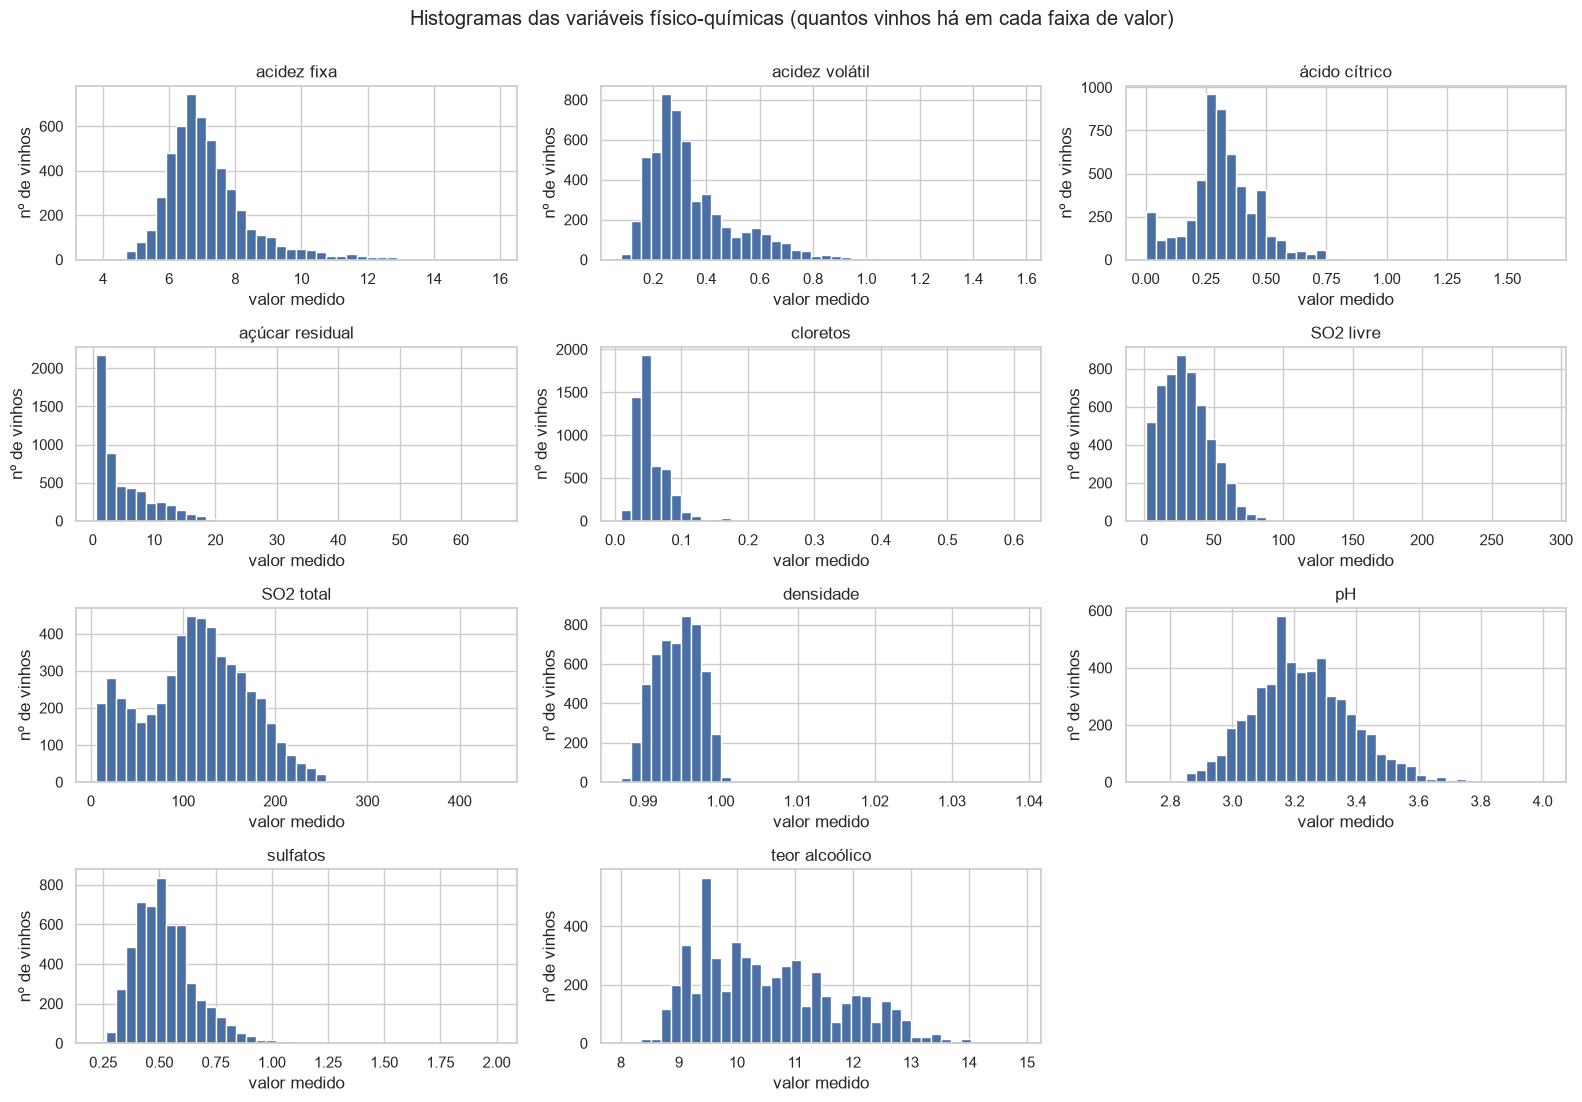

In [7]:
FEATURES_NUM = list(FAIXAS.keys())
eixos = df[FEATURES_NUM].rename(columns=NOMES_PT).hist(bins=40, figsize=(16, 11),
                                                       color="#4a6fa5", edgecolor="white")
for ax in eixos.flat:
    ax.set_xlabel("valor medido"); ax.set_ylabel("nº de vinhos")
plt.suptitle("Histogramas das variáveis físico-químicas (quantos vinhos há em cada faixa de valor)", y=1.0)
plt.tight_layout(); plt.show()

**Como ler:** cada gráfico mostra quantos vinhos (eixo vertical) têm cada faixa de valor (eixo horizontal).

**O que observamos.**
- **`açúcar residual`, `cloretos`, `acidez volátil`, `SO2 livre` e `sulfatos`** são **assimétricas à direita**: a maioria dos vinhos tem valores baixos e poucos têm valores muito altos (cauda longa). O açúcar residual é o caso mais forte: a maior parte dos vinhos fica perto de 1 a 3 g/L, mas vai até mais de 60.
- **`SO2 total`** mostra **dois "montes"** (um perto de 20–30 e outro perto de 120), compatível com a mistura de tintos e brancos, que têm perfis de SO2 diferentes.
- **`pH` e `acidez fixa`** são aproximadamente simétricas e concentradas, e **`densidade`** é muito estreita, quase toda entre 0,987 e 1,00.
- **`teor alcoólico`** é irregular, com picos em valores "redondos" (como 9,5), e **`ácido cítrico`** tem picos isolados em alguns valores.

**Por que importa.** Caudas longas significam que poucos vinhos extremos podem dominar as escalas e os coeficientes. Isso motiva a **winsorização** e a **padronização** do pré-processamento.

### 2.3 Boxplots — detecção visual de outliers

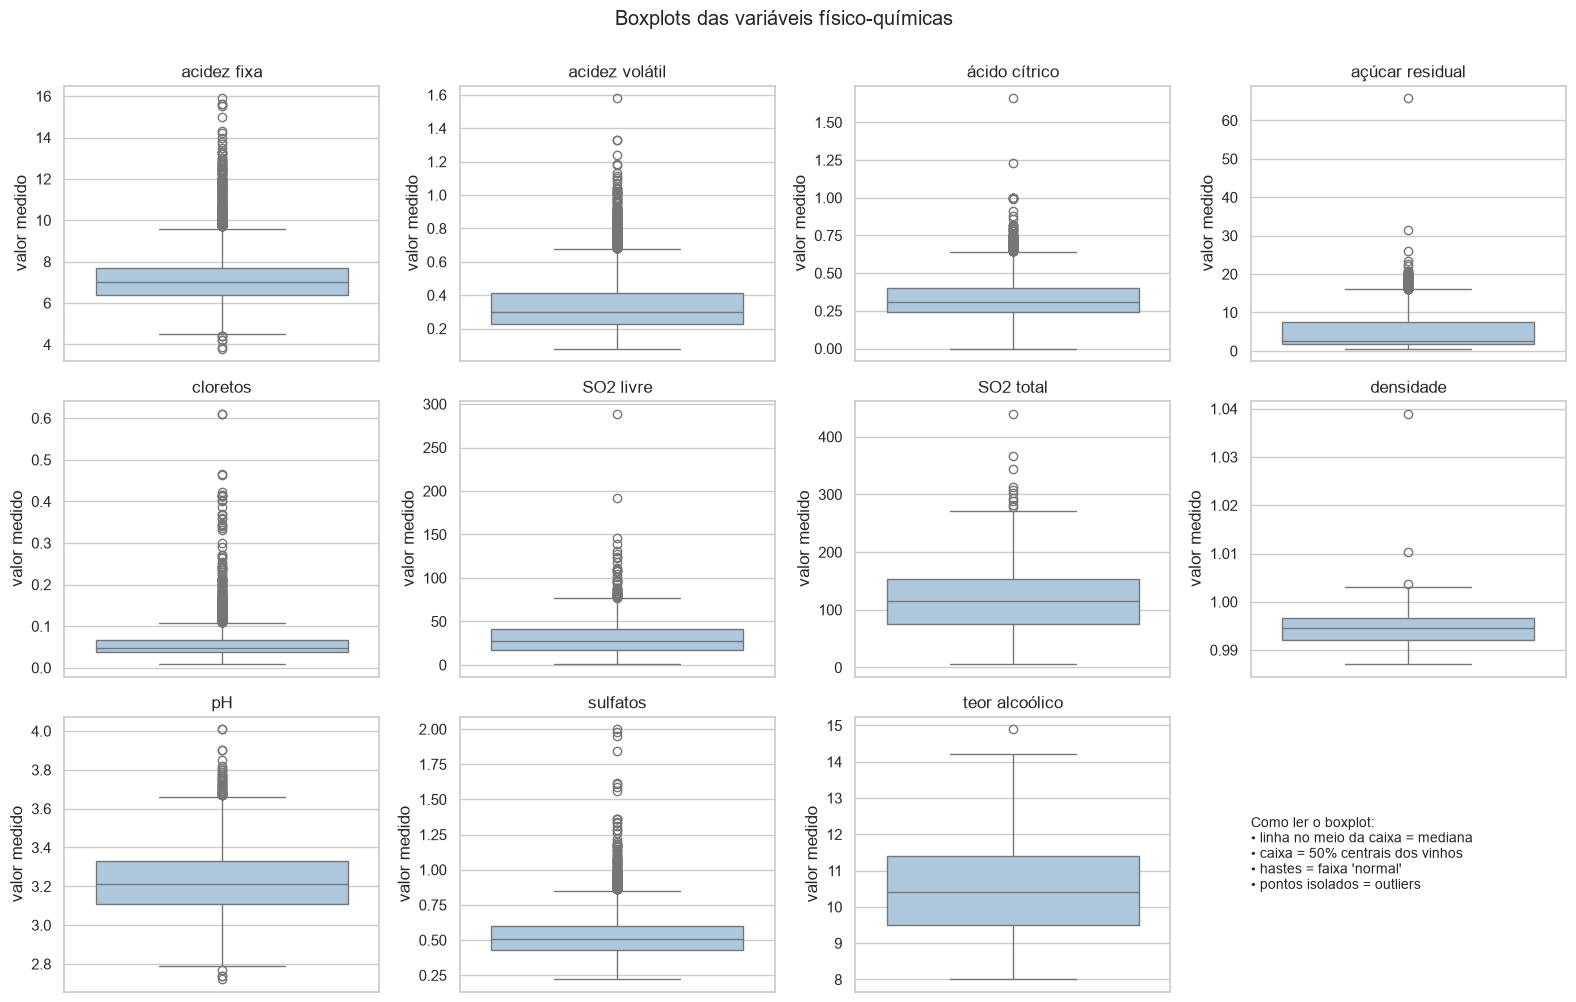

,nº de outliers (IQR)
acidez fixa,295
acidez volátil,282
cloretos,237
sulfatos,165
ácido cítrico,144
açúcar residual,144
SO2 livre,53
pH,50
SO2 total,10
densidade,3


In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATURES_NUM):
    sns.boxplot(y=df[col], ax=ax, color="#a5c8e4")
    ax.set_title(NOMES_PT[col]); ax.set_ylabel("valor medido")
axes.flat[-1].axis("off")
# Legenda de leitura no espaço vazio: caixa = 50% central dos vinhos; pontos = outliers
axes.flat[-1].text(0.0, 0.5, "Como ler o boxplot:\n• linha no meio da caixa = mediana\n"
                   "• caixa = 50% centrais dos vinhos\n• hastes = faixa 'normal'\n"
                   "• pontos isolados = outliers", fontsize=10, va="center")
plt.suptitle("Boxplots das variáveis físico-químicas", y=1.0)
plt.tight_layout(); plt.show()

# Contagem de outliers pelo critério IQR (1,5 × intervalo interquartil)
q1, q3 = df[FEATURES_NUM].quantile(0.25), df[FEATURES_NUM].quantile(0.75)
iqr = q3 - q1
outliers_iqr = ((df[FEATURES_NUM] < q1 - 1.5 * iqr) | (df[FEATURES_NUM] > q3 + 1.5 * iqr)).sum()
outliers_iqr.rename(index=NOMES_PT).sort_values(ascending=False).to_frame("nº de outliers (IQR)")

**Como ler:** a caixa cobre os 50% centrais dos vinhos, a linha dentro dela é a mediana, as hastes mostram a faixa "normal" e **cada ponto isolado é um outlier** (critério IQR: além de 1,5 × o intervalo interquartil).

**O que observamos.** As variáveis com mais outliers são `acidez fixa` (295), `acidez volátil` (282), `cloretos` (237), `sulfatos` (165), `ácido cítrico` e `açúcar residual` (144 cada). `densidade` e `teor alcoólico` quase não têm (3 e 1).

**Decisão: não remover as linhas.**
1. São vinhos **reais**, e parte deles corresponde às notas raras. Removê-los reduziria ainda mais as classes minoritárias.
2. Com 5.369 amostras, apagar centenas de linhas por variável custaria muita informação.
3. Em vez disso, aplicamos **winsorização**: cada variável é limitada aos percentis 1% e 99% do treino (dentro do pipeline). Isso corta a influência dos extremos sem perder amostras.

### 2.4 Matriz de correlação

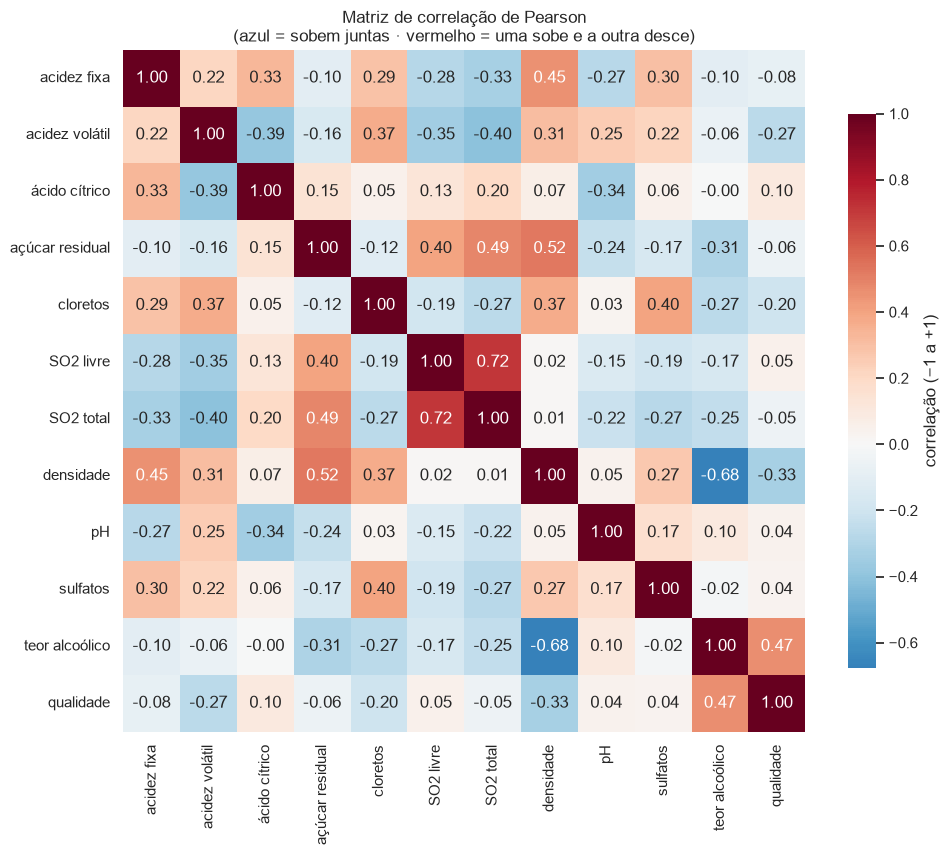

,correlação com a qualidade
teor alcoólico,0.468397
densidade,-0.332186
acidez volátil,-0.266232
cloretos,-0.202874
ácido cítrico,0.098269
acidez fixa,-0.083147
açúcar residual,-0.056488
SO2 livre,0.054858
SO2 total,-0.048026
pH,0.038028


In [9]:
corr = df[FEATURES_NUM + ["quality"]].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr.rename(index=NOMES_PT, columns=NOMES_PT), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, cbar_kws={"shrink": .8, "label": "correlação (−1 a +1)"})
plt.title("Matriz de correlação de Pearson\n(azul = sobem juntas · vermelho = uma sobe e a outra desce)")
plt.show()
corr["quality"].drop("quality").rename(index=NOMES_PT).sort_values(key=abs, ascending=False).to_frame("correlação com a qualidade")

**Como ler:** cada célula é a correlação entre duas variáveis (de −1 a +1). Azul = crescem juntas, vermelho = uma sobe e a outra desce. Perto de 0 = sem relação linear.

**O que observamos (correlação com a qualidade).**

| Variável | Correlação | Leitura |
|---|---|---|
| teor alcoólico | **+0,47** | vinhos mais alcoólicos tendem a notas maiores |
| densidade | **−0,33** | mais densos tendem a notas menores |
| acidez volátil | **−0,27** | mais "vinagre" derruba a nota |
| cloretos | −0,20 | efeito fraco, negativo |
| demais variáveis | entre −0,08 e +0,10 | praticamente nenhuma relação linear |

**Por que importa.**
- **Nenhuma variável isolada tem correlação alta** (a maior é 0,47), o que já antecipa um R² moderado.
- `teor alcoólico` e `densidade` estão relacionadas entre si (o álcool é menos denso que a água), então parte do efeito aparece nas duas. Essa **colinearidade** é um dos motivos para testar a Ridge e para interpretar coeficientes com cuidado.
- Correlação de Pearson só captura relações **lineares**. Uma variável com correlação ≈ 0 ainda pode ser útil em modelos não lineares (veremos isso no `SO2 livre`).

### 2.5 Scatter plots das variáveis mais relacionadas à qualidade

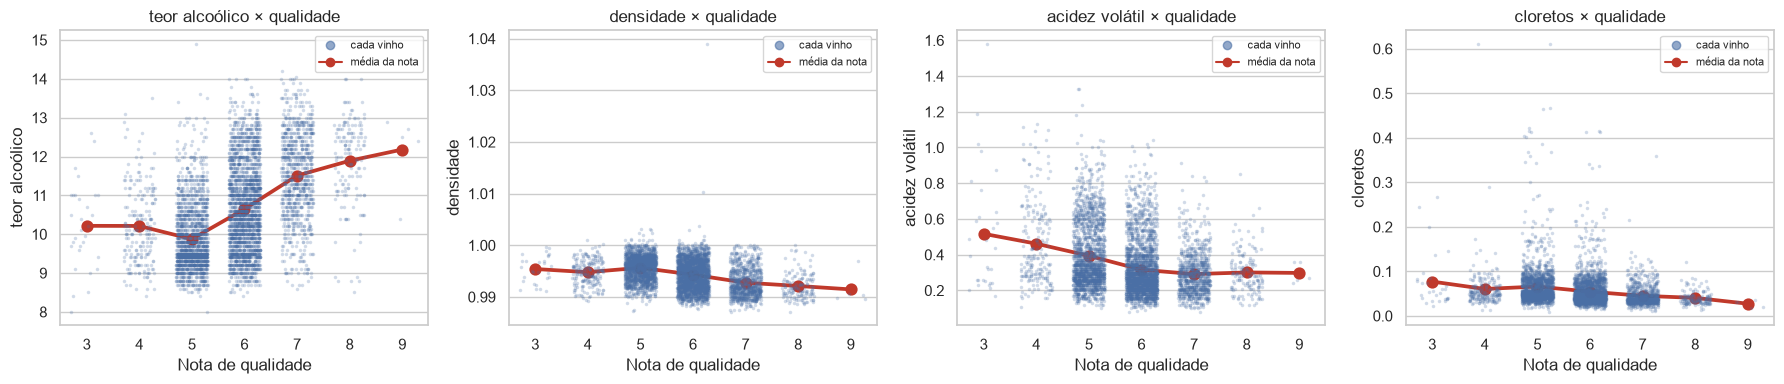

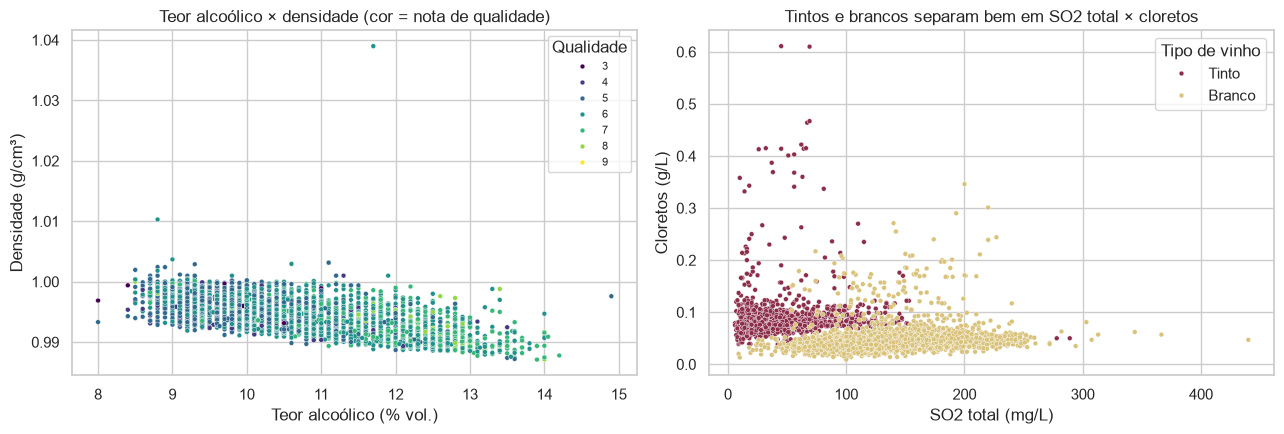

In [10]:
top4 = corr["quality"].drop("quality").abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, top4):
    sns.stripplot(x="quality", y=col, data=df, ax=ax, alpha=.25, jitter=.3, size=2.5, color="#4a6fa5")
    sns.pointplot(x="quality", y=col, data=df, ax=ax, color="#c0392b", errorbar=None)
    ax.set_title(f"{NOMES_PT[col]} × qualidade")
    ax.set_xlabel("Nota de qualidade"); ax.set_ylabel(NOMES_PT[col])
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#4a6fa5", alpha=.6, label="cada vinho"),
                       Line2D([], [], color="#c0392b", marker="o", label="média da nota")],
              fontsize=8, loc="best")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x="alcohol", y="density", hue="quality", data=df, palette="viridis", s=12, ax=ax[0])
ax[0].set_title("Teor alcoólico × densidade (cor = nota de qualidade)")
ax[0].set_xlabel("Teor alcoólico (% vol.)"); ax[0].set_ylabel("Densidade (g/cm³)")
ax[0].legend(title="Qualidade", fontsize=8)
sns.scatterplot(x="total sulfur dioxide", y="chlorides", hue="tipo_pt", data=df, s=12, ax=ax[1],
                palette=CORES_TIPO)
ax[1].set_title("Tintos e brancos separam bem em SO2 total × cloretos")
ax[1].set_xlabel("SO2 total (mg/L)"); ax[1].set_ylabel("Cloretos (g/L)")
ax[1].legend(title="Tipo de vinho")
plt.tight_layout(); plt.show()

**Como ler:** nos 4 primeiros gráficos, cada ponto azul é um vinho e a linha vermelha mostra a **média da variável em cada nota**. Nos dois últimos, a cor indica a nota (esquerda) ou o tipo de vinho (direita).

**O que observamos.**
- A média do **teor alcoólico** sobe com a nota, e a de **densidade** e **acidez volátil** desce, o que confirma as correlações.
- Mesmo assim há **grande sobreposição** entre as notas: vinhos com a mesma nota têm valores muito diferentes. Isso explica por que as variáveis químicas separam as notas só em parte.
- No gráfico de **SO2 total × cloretos**, **tintos e brancos se separam bem** em grupos distintos, o que justifica manter `type` como variável do modelo.

**Por que importa.** O cenário é de sinal real, porém fraco e ruidoso. Podemos esperar modelos melhores que o baseline, mas sem previsões muito precisas.

## 3. Pré-processamento

Decisões (todas aplicadas **dentro de um `Pipeline`**, ajustadas só no treino):
1. **Ausentes** → `SimpleImputer(strategy="median")` (mediana é robusta a outliers).
2. **Outliers** → não removemos linhas (perderíamos vinhos reais e raros, inclusive das notas extremas);
   em vez disso, **limitamos (winsorização)** cada variável aos percentis 1% e 99% do treino.
3. **Padronização** → `StandardScaler` (média 0, desvio 1). Essencial para modelos lineares, SVM e KNN e
   permite comparar coeficientes entre variáveis.
4. **`type`** → `OneHotEncoder` (vira a variável binária `type_white`).

In [11]:
class LimitadorQuantis(BaseEstimator, TransformerMixin):
    """Winsorização: corta valores abaixo/acima dos quantis aprendidos no treino."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lim_inf_ = np.nanquantile(X, self.inferior, axis=0)
        self.lim_sup_ = np.nanquantile(X, self.superior, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lim_inf_, self.lim_sup_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def criar_preprocessador():
    numerico = Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("outliers", LimitadorQuantis(0.01, 0.99)),
        ("padronizacao", StandardScaler()),
    ])
    categorico = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("num", numerico, FEATURES_NUM),
        ("cat", categorico, ["type"]),
    ], verbose_feature_names_out=False)


X = df[FEATURES_NUM + ["type"]]
y = df["quality"]

# Divisão treino/teste estratificada pela nota -> mesmas proporções nos dois conjuntos.
# O conjunto de teste só é usado no final, para a avaliação definitiva.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("treino:", X_train.shape, "| teste:", X_test.shape)

treino: (4295, 12) | teste: (1074, 12)


## 4. Parte 1 — Regressão (predição da nota)

### 4.1 Modelos e validação cruzada
Comparamos um **baseline** (prevê sempre a média) com quatro modelos:
- **Regressão Linear** — simples e interpretável (coeficientes);
- **Ridge** — linear com regularização L2 (lida melhor com variáveis correlacionadas, como density × alcohol);
- **Random Forest** — conjunto de árvores, captura não linearidades e interações;
- **HistGradientBoosting** — boosting de árvores, geralmente o mais forte em dados tabulares.

Métricas: **RMSE** (penaliza erros grandes, na unidade da nota), **MAE** (erro médio absoluto) e
**R²** (fração da variância explicada). Validação cruzada com 5 folds no treino.

In [12]:
modelos_reg = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Regressão Linear": LinearRegression(),
    "Ridge": Ridge(random_state=SEED),
    "Random Forest": RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_reg = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

linhas = []
for nome, modelo in modelos_reg.items():
    pipe = Pipeline([("prep", criar_preprocessador()), ("modelo", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=cv_reg, scoring=metricas_reg, n_jobs=-1)
    linhas.append({"Modelo": nome,
                   "RMSE": -res["test_RMSE"].mean(), "MAE": -res["test_MAE"].mean(),
                   "R²": res["test_R2"].mean(), "R² (desvio)": res["test_R2"].std()})
resultado_cv_reg = pd.DataFrame(linhas).set_index("Modelo").round(4)
resultado_cv_reg

,RMSE,MAE,R²,R² (desvio)
Modelo,,,,
Baseline (média),0.8808,0.6954,-0.0039,0.0057
Regressão Linear,0.7316,0.5658,0.3065,0.0303
Ridge,0.7316,0.5658,0.3065,0.0302
Random Forest,0.6903,0.5275,0.3824,0.0352
HistGradientBoosting,0.7010,0.5401,0.3627,0.0435


**O que foi feito.** Comparamos 4 modelos com validação cruzada de 5 folds no treino, contra um **baseline** que sempre prevê a nota média.

| Modelo | RMSE | MAE | R² |
|---|---|---|---|
| Baseline (média) | 0,881 | 0,695 | −0,004 |
| Regressão Linear | 0,732 | 0,566 | 0,307 |
| Ridge | 0,732 | 0,566 | 0,307 |
| **Random Forest** | **0,690** | **0,528** | **0,382** |
| HistGradientBoosting | 0,701 | 0,540 | 0,363 |

**Interpretação.**
- Todos os modelos **superam o baseline**, cujo R² ≈ 0 mostra que "chutar a média" não explica nada. O Random Forest reduz o RMSE em cerca de **22%** em relação a ele.
- **Linear e Ridge empatam**: a regularização quase não muda nada, porque os dados já são padronizados e há pouca instabilidade nos coeficientes.
- Os modelos de **árvores vencem os lineares** (R² 0,36–0,38 contra 0,31), um sinal de que existem **relações não lineares e interações** entre as variáveis que a reta não captura.
- O desvio do R² entre os folds é pequeno (≈ 0,03–0,04), então o resultado é estável.

### 4.2 Ajuste de hiperparâmetros (GridSearchCV)
Otimizamos o RMSE (via `neg_root_mean_squared_error`) com validação cruzada de 5 folds.

In [13]:
grades_reg = {
    "Ridge": (Ridge(random_state=SEED),
              {"modelo__alpha": [0.01, 0.1, 1, 10, 50, 100]}),
    "Random Forest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                      {"modelo__n_estimators": [200, 400],
                       "modelo__max_depth": [None, 20],
                       "modelo__min_samples_leaf": [1, 3],
                       "modelo__max_features": ["sqrt", 0.5]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=SEED),
                             {"modelo__learning_rate": [0.03, 0.1],
                              "modelo__max_iter": [200, 500],
                              "modelo__max_leaf_nodes": [15, 31],
                              "modelo__l2_regularization": [0.0, 1.0]}),
}

melhores_reg = {}
for nome, (modelo, grade) in grades_reg.items():
    busca = GridSearchCV(Pipeline([("prep", criar_preprocessador()), ("modelo", modelo)]),
                         grade, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=-1)
    busca.fit(X_train, y_train)
    melhores_reg[nome] = busca.best_estimator_
    print(f"{nome:22s} RMSE CV = {-busca.best_score_:.4f}  |  {busca.best_params_}")

Ridge                  RMSE CV = 0.7316  |  {'modelo__alpha': 10}


Random Forest          RMSE CV = 0.6798  |  {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}


HistGradientBoosting   RMSE CV = 0.6944  |  {'modelo__l2_regularization': 1.0, 'modelo__learning_rate': 0.03, 'modelo__max_iter': 200, 'modelo__max_leaf_nodes': 31}


### 4.3 Avaliação final no conjunto de teste

In [14]:
melhores_reg["Regressão Linear"] = Pipeline([("prep", criar_preprocessador()),
                                             ("modelo", LinearRegression())]).fit(X_train, y_train)
linhas = []
for nome, pipe in melhores_reg.items():
    pred = pipe.predict(X_test)
    linhas.append({"Modelo": nome, "RMSE": root_mean_squared_error(y_test, pred),
                   "MAE": mean_absolute_error(y_test, pred), "R²": r2_score(y_test, pred),
                   "Acerto ao arredondar": (np.clip(np.round(pred), 3, 9) == y_test).mean()})
resultado_teste_reg = pd.DataFrame(linhas).set_index("Modelo").sort_values("RMSE").round(4)
resultado_teste_reg

,RMSE,MAE,R²,Acerto ao arredondar
Modelo,,,,
Random Forest,0.6911,0.5316,0.3817,0.5754
HistGradientBoosting,0.6995,0.5435,0.3666,0.5531
Regressão Linear,0.7353,0.5705,0.3001,0.5354
Ridge,0.7354,0.5705,0.3000,0.5354


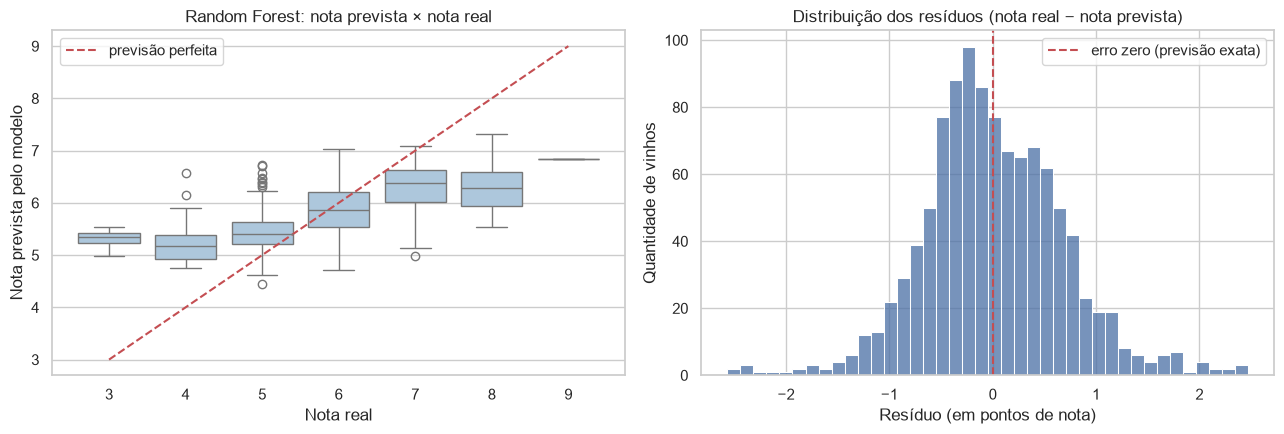

In [15]:
melhor_nome_reg = resultado_teste_reg.index[0]
melhor_reg = melhores_reg[melhor_nome_reg]
pred = melhor_reg.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=y_test, y=pred, ax=ax[0], color="#a5c8e4")
notas = np.sort(y_test.unique())
ax[0].plot(range(len(notas)), notas, "r--", label="previsão perfeita")
ax[0].set_xlabel("Nota real"); ax[0].set_ylabel("Nota prevista pelo modelo")
ax[0].set_title(f"{melhor_nome_reg}: nota prevista × nota real"); ax[0].legend()
sns.histplot(y_test - pred, bins=40, ax=ax[1], color="#4a6fa5")
ax[1].axvline(0, color="r", ls="--", label="erro zero (previsão exata)")
ax[1].set_title("Distribuição dos resíduos (nota real − nota prevista)")
ax[1].set_xlabel("Resíduo (em pontos de nota)"); ax[1].set_ylabel("Quantidade de vinhos")
ax[1].legend()
plt.tight_layout(); plt.show()

**Resultado final no teste** (dados que o modelo nunca viu), depois do GridSearchCV:

| Modelo | RMSE | MAE | R² | Acerto ao arredondar |
|---|---|---|---|---|
| **Random Forest** | **0,691** | **0,532** | **0,382** | **57,5%** |
| HistGradientBoosting | 0,700 | 0,544 | 0,367 | 55,3% |
| Regressão Linear | 0,735 | 0,571 | 0,300 | 53,5% |
| Ridge | 0,735 | 0,571 | 0,300 | 53,5% |

O melhor é o **Random Forest** (400 árvores, `max_features='sqrt'`). O resultado do teste é quase igual ao da validação cruzada (RMSE 0,680 contra 0,691), o que indica **pouco sobreajuste**. Em média o modelo erra cerca de **meio ponto de nota** (MAE 0,53).

**Como ler os gráficos.**
- **Nota prevista × real (esquerda):** se o modelo fosse perfeito, as caixas ficariam sobre a linha tracejada. Elas ficam **achatadas e acima da linha nas notas baixas e abaixo dela nas notas altas**: vinhos de nota 3 e 4 são previstos perto de 5, e vinhos de nota 8 e 9 são previstos perto de 6 a 7. O modelo quase nunca prevê abaixo de 4,5 ou acima de 7,3. Isso é a **regressão à média**: na dúvida, o modelo se aproxima do valor mais comum (5 a 6), o que acontece porque as pontas têm poucos exemplos e as variáveis químicas não bastam para distingui-las.
- **Resíduos (direita):** o histograma é aproximadamente **simétrico e centrado em zero**, com a maioria dos erros dentro de ±1 ponto. Ou seja, não há viés geral, e os erros grandes (±2) são raros.

**Por que o R² "baixo" (≈ 0,38) é aceitável.** A nota é uma **avaliação sensorial subjetiva** de provadores. Duas pessoas podem dar notas diferentes para o mesmo vinho. As medidas químicas explicam cerca de 38% da variação, e o restante depende de aroma, sabor e opinião, que não estão no arquivo.

### 4.4 Interpretação — quais variáveis mais impactam a nota?
**Coeficientes da Regressão Linear:** como as variáveis foram padronizadas, cada coeficiente indica
quanto a nota muda quando a variável aumenta **1 desvio-padrão**, mantendo as demais constantes.

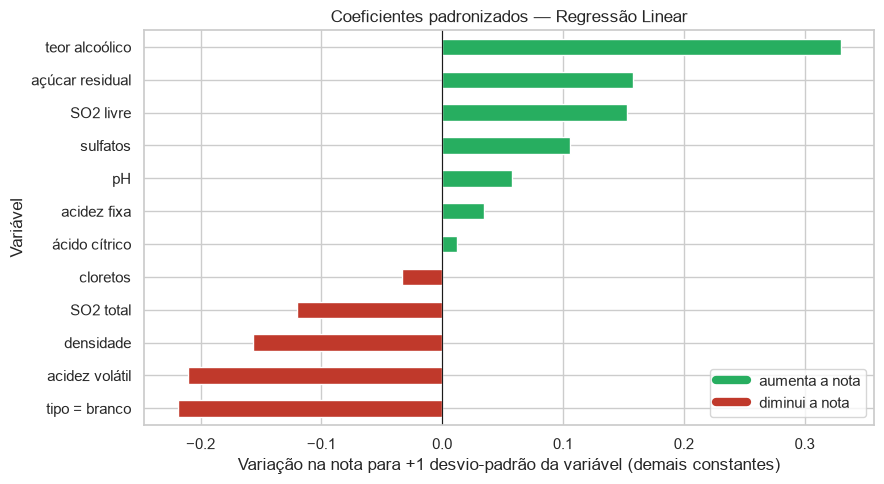

,Linear,Ridge
teor alcoólico,0.330,0.332
cloretos,-0.033,-0.033
ácido cítrico,0.013,0.013
densidade,-0.156,-0.150
acidez fixa,0.035,0.034
SO2 livre,0.153,0.153
pH,0.058,0.058
açúcar residual,0.158,0.153
sulfatos,0.106,0.106
SO2 total,-0.120,-0.122


In [16]:
lin = melhores_reg["Regressão Linear"]
coef = pd.Series(lin.named_steps["modelo"].coef_,
                 index=lin.named_steps["prep"].get_feature_names_out()).sort_values()
ridge = melhores_reg["Ridge"]
coef_ridge = pd.Series(ridge.named_steps["modelo"].coef_,
                       index=ridge.named_steps["prep"].get_feature_names_out())

fig, ax = plt.subplots(figsize=(9, 5))
coef.rename(index=NOMES_PT).plot.barh(ax=ax, color=["#c0392b" if c < 0 else "#27ae60" for c in coef])
ax.set_title("Coeficientes padronizados — Regressão Linear"); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Variação na nota para +1 desvio-padrão da variável (demais constantes)")
ax.set_ylabel("Variável")
ax.legend(handles=[Line2D([], [], color="#27ae60", lw=6, label="aumenta a nota"),
                   Line2D([], [], color="#c0392b", lw=6, label="diminui a nota")], loc="lower right")
plt.tight_layout(); plt.show()
pd.DataFrame({"Linear": coef, "Ridge": coef_ridge}).rename(index=NOMES_PT).round(3)

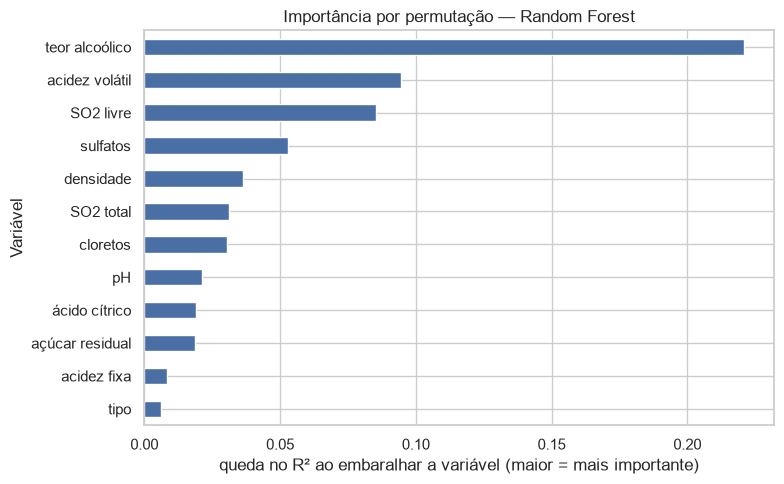

,queda no R²
teor alcoólico,0.2209
acidez volátil,0.0944
SO2 livre,0.0853
sulfatos,0.0529
densidade,0.0362
SO2 total,0.0311
cloretos,0.0303
pH,0.0212
ácido cítrico,0.0190
açúcar residual,0.0188


In [17]:
# Importância por permutação no teste: quanto o R² cai ao embaralhar cada variável.
# Funciona para qualquer modelo e é mais confiável que a importância "impurity" das árvores.
imp = permutation_importance(melhor_reg, X_test, y_test, n_repeats=10, random_state=SEED,
                             scoring="r2", n_jobs=-1)
imp_reg = pd.Series(imp.importances_mean, index=X_test.columns).rename(index=NOMES_PT).sort_values()
imp_reg.plot.barh(figsize=(8, 5), color="#4a6fa5",
                  title=f"Importância por permutação — {melhor_nome_reg}")
plt.xlabel("queda no R² ao embaralhar a variável (maior = mais importante)")
plt.ylabel("Variável"); plt.tight_layout(); plt.show()
imp_reg.sort_values(ascending=False).round(4).to_frame("queda no R²")

### 4.5 Discussão da regressão
**Duas formas de interpretar quais variáveis importam.**

**1) Coeficientes da Regressão Linear** (padronizados: efeito na nota por +1 desvio-padrão, mantendo as demais constantes):

| Variável | Coeficiente | Leitura |
|---|---|---|
| teor alcoólico | **+0,33** | o maior efeito: mais álcool, nota maior |
| tipo = branco | −0,22 | a perfil químico igual, brancos recebem notas ligeiramente menores |
| acidez volátil | **−0,21** | mais acidez volátil, nota menor |
| açúcar residual | +0,16 | ver nota abaixo |
| densidade | −0,16 | mais densidade, nota menor |
| SO2 livre | +0,15 | mais SO2 livre, nota maior |
| SO2 total | −0,12 | mais SO2 total, nota menor |

Ridge e Linear dão praticamente os mesmos valores.

**2) Importância por permutação no Random Forest** (quanto o R² cai ao embaralhar a variável): `teor alcoólico` domina (queda de ≈ 0,22), seguido por `acidez volátil` (≈ 0,09), `SO2 livre` (≈ 0,09), `sulfatos` (≈ 0,05) e `densidade` (≈ 0,04). `tipo` e `acidez fixa` quase não contribuem.

**Pontos de atenção (úteis para a banca).**
- **`açúcar residual` tem coeficiente positivo**, embora sua correlação simples com a nota seja levemente negativa (−0,06). Isso é efeito da **colinearidade com a densidade**: açúcar aumenta a densidade e, **mantida a densidade fixa**, mais açúcar passa a estar associado a notas maiores. O coeficiente deve ser lido com "demais variáveis constantes", e não como causa isolada.
- **`SO2 livre` (+) e `SO2 total` (−)** têm sinais opostos porque o SO2 livre é parte do total. O que penaliza a nota é o SO2 "combinado" (total menos livre).
- **`SO2 livre` é bem importante para o Random Forest**, mesmo tendo correlação linear quase nula (+0,05) com a nota. Isso mostra uma relação **não linear** que só o modelo de árvores captura, e é uma razão a mais para ele superar os lineares.
- **Em ambos os métodos, o álcool é a variável mais importante**, seguido pela acidez volátil. Isso é coerente com o que a EDA já indicava.

## 5. Parte 2 — Classificação (faixas de qualidade)

### 5.1 Criação da variável alvo categórica — testando diferentes faixas
O enunciado pede para testar diferentes *ranges*. Testamos três discretizações:

| Esquema | Faixas | Ideia |
|---|---|---|
| **A** | baixa (0–4) · média (5–6) · alta (7–10) | faixas "naturais" da escala sensorial |
| **B** | baixa (0–5) · média (6) · alta (7–10) | divide a massa central, classes menos desiguais |
| **C** | ruim (0–5) · bom (6–10) | binário, o mais equilibrado |

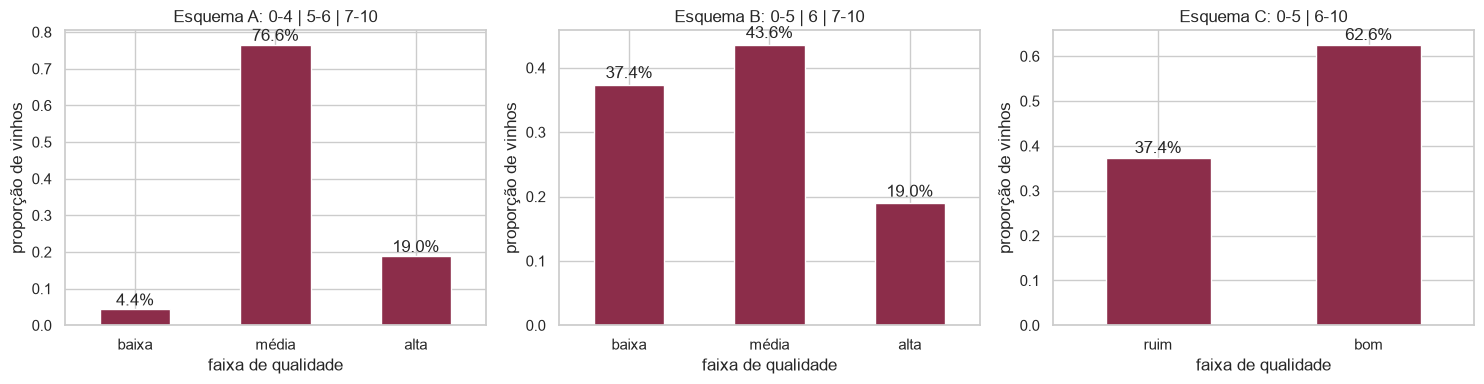

In [18]:
ESQUEMAS = {
    "A: 0-4 | 5-6 | 7-10": ([0, 4, 6, 10], ["baixa", "média", "alta"]),
    "B: 0-5 | 6 | 7-10":   ([0, 5, 6, 10], ["baixa", "média", "alta"]),
    "C: 0-5 | 6-10":       ([0, 5, 10], ["ruim", "bom"]),
}


def discretizar(notas, esquema):
    limites, rotulos = ESQUEMAS[esquema]
    return pd.cut(notas, bins=limites, labels=rotulos, include_lowest=True).astype(str)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, esquema in zip(axes, ESQUEMAS):
    dist = discretizar(df["quality"], esquema).value_counts(normalize=True)[ESQUEMAS[esquema][1]]
    dist.plot.bar(ax=ax, color="#8c2d4a", rot=0)
    ax.set_title(f"Esquema {esquema}"); ax.set_ylabel("proporção de vinhos")
    ax.set_xlabel("faixa de qualidade")
    for i, v in enumerate(dist):
        ax.text(i, v + .01, f"{v:.1%}", ha="center")
plt.tight_layout(); plt.show()

**Como ler:** cada gráfico mostra a proporção de vinhos em cada faixa para um dos três esquemas.

- **Esquema A (0–4 | 5–6 | 7–10):** muito desbalanceado. No treino, "média" tem 3.290 vinhos (≈ 77%), "alta" 815 (≈ 19%) e "baixa" apenas 190 (≈ 4%).
- **Esquema B (0–5 | 6 | 7–10):** divide a massa central, e as classes ficam menos desiguais.
- **Esquema C (0–5 | 6–10):** binário, o mais equilibrado.

**Por que importa.** Quanto mais desbalanceado o esquema, mais "fácil" é acertar apenas prevendo a classe grande, e mais enganosa fica a acurácia.

### 5.2 Escolha da métrica
Como as classes são **desbalanceadas**, a acurácia engana: um modelo que só prevê "média" já
acerta a maioria. Usamos o **F1-macro** como métrica principal — a média do F1 de cada classe, com
**peso igual** para todas — e a **acurácia balanceada** (média do recall por classe) como apoio.
Assim, errar todos os vinhos de qualidade baixa ou alta é punido de verdade.

### 5.3 Comparação inicial: 4 classificadores × 3 esquemas
Classificadores: **Regressão Logística**, **SVM (RBF)**, **Random Forest** e **HistGradientBoosting**,
todos com `class_weight="balanced"` (dá mais peso às classes raras) e um baseline que sempre
prevê a classe majoritária. Os rótulos de texto são convertidos em números com `LabelEncoder`.

In [19]:
def classificadores():
    return {
        "Baseline (majoritária)": DummyClassifier(strategy="most_frequent"),
        "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "SVM (RBF)": SVC(class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    }


cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
linhas = []
for esquema in ESQUEMAS:
    # mesmo split do treino/teste da regressão (mesmos índices)
    y_tr = LabelEncoder().fit(ESQUEMAS[esquema][1]).transform(discretizar(y_train, esquema))
    for nome, modelo in classificadores().items():
        pipe = Pipeline([("prep", criar_preprocessador()), ("modelo", modelo)])
        res = cross_validate(pipe, X_train, y_tr, cv=cv_clf, n_jobs=-1,
                             scoring={"f1": "f1_macro", "bal": "balanced_accuracy", "acc": "accuracy"})
        linhas.append({"Esquema": esquema, "Modelo": nome, "F1-macro": res["test_f1"].mean(),
                       "Acur. balanceada": res["test_bal"].mean(), "Acurácia": res["test_acc"].mean()})
comparacao = pd.DataFrame(linhas).round(4)
comparacao.pivot(index="Modelo", columns="Esquema", values="F1-macro")

Esquema,A: 0-4 | 5-6 | 7-10,B: 0-5 | 6 | 7-10,C: 0-5 | 6-10
Modelo,,,
Baseline (majoritária),0.2892,0.2024,0.3849
HistGradientBoosting,0.5451,0.5931,0.7385
Random Forest,0.5604,0.5993,0.7533
Regressão Logística,0.4533,0.5543,0.7245
SVM (RBF),0.5039,0.5748,0.7366


In [20]:
comparacao.set_index(["Esquema", "Modelo"])

F1-macro  Acur. balanceada  \
Esquema             Modelo                                               
A: 0-4 | 5-6 | 7-10 Baseline (majoritária)    0.2892            0.3333   
                    Regressão Logística       0.4533            0.6313   
                    SVM (RBF)                 0.5039            0.6536   
                    Random Forest             0.5604            0.5564   
                    HistGradientBoosting      0.5451            0.5356   
B: 0-5 | 6 | 7-10   Baseline (majoritária)    0.2024            0.3333   
                    Regressão Logística       0.5543            0.5953   
                    SVM (RBF)                 0.5748            0.6150   
                    Random Forest             0.5993            0.6070   
                    HistGradientBoosting      0.5931            0.5986   
C: 0-5 | 6-10       Baseline (majoritária)    0.3849            0.5000   
                    Regressão Logística       0.7245            0.7362   
                    SVM (RBF)                 0.7366            0.7484   
                    Random Forest             0.7533            0.7559   
                    HistGradientBoosting      0.7385            0.7434   

                                            Acurácia  
Esquema             Modelo                            
A: 0-4 | 5-6 | 7-10 Baseline (majoritária)    0.7660  
                    Regressão Logística       0.5378  
                    SVM (RBF)                 0.6149  
                    Random Forest             0.7669  
                    HistGradientBoosting      0.7695  
B: 0-5 | 6 | 7-10   Baseline (majoritária)    0.4361  
                    Regressão Logística       0.5583  
                    SVM (RBF)                 0.5788  
                    Random Forest             0.6061  
                    HistGradientBoosting      0.5981  
C: 0-5 | 6-10       Baseline (majoritária)    0.6258  
                    Regressão Logística       0.7327  
                    SVM (RBF)                 0.7446  
                    Random Forest             0.7669  
                    HistGradientBoosting      0.7509

**F1-macro por modelo e esquema (validação cruzada):**

| Modelo | A (3 faixas) | B (3 faixas) | C (2 faixas) |
|---|---|---|---|
| Baseline (majoritária) | 0,289 | 0,202 | 0,385 |
| Regressão Logística | 0,453 | 0,554 | 0,725 |
| SVM (RBF) | 0,504 | 0,575 | 0,737 |
| **Random Forest** | **0,560** | **0,599** | **0,753** |
| HistGradientBoosting | 0,545 | 0,593 | 0,739 |

**Interpretação.**
- O **Random Forest é o melhor em todos os esquemas**, com o HistGradientBoosting logo atrás.
- O F1-macro **sobe quando há menos classes**: C (≈ 0,75) > B (≈ 0,60) > A (≈ 0,56). Não significa que C é "melhor", só que é um problema mais fácil. Ele ignora a diferença entre vinhos ruins e medianos.
- **Prova de que a acurácia engana:** no esquema A, o baseline que só prevê "média" tem **acurácia de 76,6%**, praticamente igual à dos melhores modelos (≈ 77%), mas seu **F1-macro é só 0,29**. Um modelo inútil parece bom pela acurácia, e por isso usamos o **F1-macro**.

**Esquema escolhido: A.** Ele preserva as três faixas naturais da escala sensorial (baixa, média, alta) e mantém a classe rara "baixa", que é onde o desbalanceamento realmente aparece e onde o trabalho de balanceamento tem mais efeito.

### 5.4 Esquema principal e balanceamento de classes
Aprofundamos no esquema **A: 0-4 | 5-6 | 7-10**. Comparamos três estratégias para lidar com o
desbalanceamento, usando o Random Forest:
1. **Nenhum ajuste**;
2. **`class_weight="balanced"`** — pesos inversamente proporcionais à frequência da classe;
3. **SMOTE** (oversampling sintético) — cria exemplos artificiais das classes raras **apenas nos folds
   de treino** (por isso usamos o `Pipeline` do `imblearn`; aplicar SMOTE antes do split vazaria dados).

In [21]:
ESQ = "A: 0-4 | 5-6 | 7-10"
codificador = LabelEncoder().fit(ESQUEMAS[ESQ][1])
y_train_c = codificador.transform(discretizar(y_train, ESQ))
y_test_c = codificador.transform(discretizar(y_test, ESQ))
# LabelEncoder numera as classes em ordem alfabética
print("Classes codificadas:", {str(c): int(i) for c, i in zip(codificador.classes_,
                                                            codificador.transform(codificador.classes_))})
print("Distribuição no treino:", pd.Series(codificador.inverse_transform(y_train_c)).value_counts().to_dict())

estrategias = {
    "Sem ajuste": ImbPipeline([("prep", criar_preprocessador()),
                               ("modelo", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
    "class_weight=balanced": ImbPipeline([("prep", criar_preprocessador()),
                                          ("modelo", RandomForestClassifier(class_weight="balanced",
                                                                            random_state=SEED, n_jobs=-1))]),
    "SMOTE": ImbPipeline([("prep", criar_preprocessador()), ("smote", SMOTE(random_state=SEED)),
                          ("modelo", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
}
linhas = []
for nome, pipe in estrategias.items():
    res = cross_validate(pipe, X_train, y_train_c, cv=cv_clf, n_jobs=-1,
                         scoring={"f1": "f1_macro", "bal": "balanced_accuracy"})
    linhas.append({"Estratégia": nome, "F1-macro": res["test_f1"].mean(),
                   "Acur. balanceada": res["test_bal"].mean()})
pd.DataFrame(linhas).set_index("Estratégia").round(4)

Classes codificadas: {'alta': 0, 'baixa': 1, 'média': 2}
Distribuição no treino: {'média': 3290, 'alta': 815, 'baixa': 190}


,F1-macro,Acur. balanceada
Estratégia,,
Sem ajuste,0.4828,0.4620
class_weight=balanced,0.5604,0.5564
SMOTE,0.5535,0.5633


**Comparação com o Random Forest no esquema A (validação cruzada):**

| Estratégia | F1-macro | Acurácia balanceada |
|---|---|---|
| Sem ajuste | 0,483 | 0,462 |
| `class_weight="balanced"` | **0,560** | 0,556 |
| SMOTE | 0,554 | **0,563** |

**Interpretação.**
- Sem nenhum ajuste, o modelo **ignora as classes raras**: o recall delas é baixo e o F1-macro fica em 0,48.
- Tratar o desbalanceamento traz um ganho de cerca de **7 pontos de F1-macro**, o maior ganho individual de toda a classificação.
- `class_weight` e **SMOTE** têm efeito praticamente equivalente (a diferença de 0,006 está dentro da variação esperada). O `class_weight` é mais simples e não cria dados artificiais.
- O SMOTE foi aplicado **somente dentro do pipeline**, nos folds de treino. Se ele fosse aplicado antes da divisão, exemplos sintéticos (derivados de vinhos que acabariam no teste) vazariam para a validação e inflariam o resultado.

### 5.5 Ajuste de hiperparâmetros (GridSearchCV, F1-macro)

In [22]:
grades_clf = {
    "Regressão Logística": (
        ImbPipeline([("prep", criar_preprocessador()), ("smote", SMOTE(random_state=SEED)),
                     ("modelo", LogisticRegression(max_iter=3000))]),
        {"smote": [SMOTE(random_state=SEED), "passthrough"],
         "modelo__C": [0.01, 0.1, 1, 10],
         "modelo__class_weight": [None, "balanced"]}),
    "SVM (RBF)": (
        ImbPipeline([("prep", criar_preprocessador()), ("smote", "passthrough"),
                     ("modelo", SVC(class_weight="balanced", random_state=SEED))]),
        {"modelo__C": [1, 10, 30], "modelo__gamma": ["scale", 0.1, 0.3]}),
    "Random Forest": (
        ImbPipeline([("prep", criar_preprocessador()), ("smote", "passthrough"),
                     ("modelo", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
        {"smote": [SMOTE(random_state=SEED), "passthrough"],
         "modelo__class_weight": [None, "balanced_subsample"],
         "modelo__n_estimators": [300],
         "modelo__max_depth": [None, 15],
         "modelo__min_samples_leaf": [1, 3]}),
    "HistGradientBoosting": (
        ImbPipeline([("prep", criar_preprocessador()), ("smote", "passthrough"),
                     ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))]),
        {"modelo__learning_rate": [0.05, 0.1],
         "modelo__max_iter": [200, 400],
         "modelo__max_leaf_nodes": [15, 31]}),
}

melhores_clf, linhas = {}, []
for nome, (pipe, grade) in grades_clf.items():
    busca = GridSearchCV(pipe, grade, cv=cv_clf, scoring="f1_macro", n_jobs=-1)
    busca.fit(X_train, y_train_c)
    melhores_clf[nome] = busca.best_estimator_
    print(f"{nome:22s} F1-macro CV = {busca.best_score_:.4f}  |  {busca.best_params_}")

Regressão Logística    F1-macro CV = 0.4573  |  {'modelo__C': 1, 'modelo__class_weight': None, 'smote': SMOTE(random_state=42)}


SVM (RBF)              F1-macro CV = 0.5440  |  {'modelo__C': 1, 'modelo__gamma': 0.3}


Random Forest          F1-macro CV = 0.5671  |  {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 15, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 300, 'smote': SMOTE(random_state=42)}


HistGradientBoosting   F1-macro CV = 0.5596  |  {'modelo__learning_rate': 0.05, 'modelo__max_iter': 200, 'modelo__max_leaf_nodes': 15}


### 5.6 Avaliação final no conjunto de teste

In [23]:
linhas = []
for nome, pipe in melhores_clf.items():
    pred_c = pipe.predict(X_test)
    linhas.append({"Modelo": nome, "F1-macro": f1_score(y_test_c, pred_c, average="macro"),
                   "Acur. balanceada": balanced_accuracy_score(y_test_c, pred_c),
                   "Acurácia": (pred_c == y_test_c).mean()})
resultado_teste_clf = pd.DataFrame(linhas).set_index("Modelo").sort_values("F1-macro", ascending=False).round(4)
resultado_teste_clf

,F1-macro,Acur. balanceada,Acurácia
Modelo,,,
HistGradientBoosting,0.5762,0.6321,0.7318
Random Forest,0.5684,0.6198,0.7346
SVM (RBF),0.5567,0.6527,0.6937
Regressão Logística,0.4545,0.6458,0.5382


Melhor modelo: HistGradientBoosting

              precision    recall  f1-score   support

        alta      0.483     0.691     0.569       204
       baixa      0.280     0.447     0.344        47
       média      0.883     0.758     0.816       823

    accuracy                          0.732      1074
   macro avg      0.548     0.632     0.576      1074
weighted avg      0.780     0.732     0.748      1074



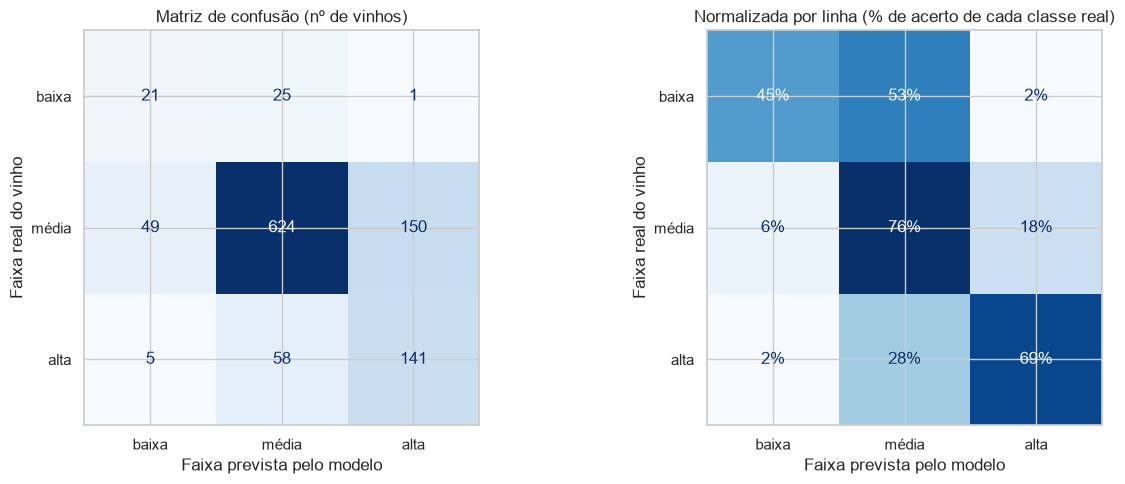

In [24]:
melhor_nome_clf = resultado_teste_clf.index[0]
melhor_clf = melhores_clf[melhor_nome_clf]
pred_c = melhor_clf.predict(X_test)
print(f"Melhor modelo: {melhor_nome_clf}\n")
print(classification_report(y_test_c, pred_c, target_names=codificador.classes_, digits=3))

ordem = ESQUEMAS[ESQ][1]
idx = codificador.transform(ordem)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_c, labels=idx, display_labels=ordem,
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Matriz de confusão (nº de vinhos)")
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_c, labels=idx, display_labels=ordem,
                                        normalize="true", values_format=".0%", cmap="Blues",
                                        ax=ax[1], colorbar=False)
ax[1].set_title("Normalizada por linha (% de acerto de cada classe real)")
for a in ax:   # linhas = classe real, colunas = classe prevista; diagonal = acertos
    a.set_xlabel("Faixa prevista pelo modelo"); a.set_ylabel("Faixa real do vinho")
plt.tight_layout(); plt.show()

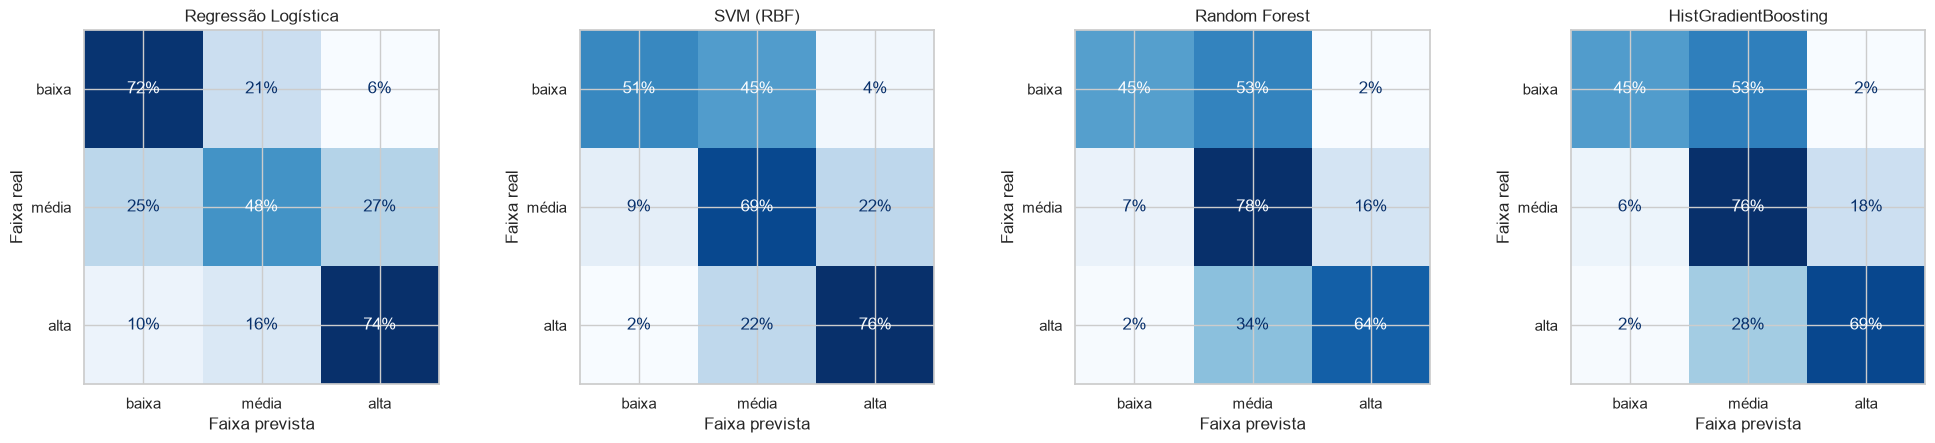

In [25]:
# Matrizes de confusão de todos os modelos ajustados, para comparar os padrões de erro
fig, axes = plt.subplots(1, len(melhores_clf), figsize=(5 * len(melhores_clf), 4.5))
for ax, (nome, pipe) in zip(axes, melhores_clf.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_c, pipe.predict(X_test), labels=idx,
                                            display_labels=ordem, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel("Faixa prevista"); ax.set_ylabel("Faixa real")
plt.tight_layout(); plt.show()

In [26]:
# Quais notas originais são mais confundidas? (erros do melhor modelo por nota real)
erros = pd.DataFrame({"nota": y_test.values, "real": codificador.inverse_transform(y_test_c),
                      "previsto": codificador.inverse_transform(pred_c)})
erros["acertou"] = erros["real"] == erros["previsto"]
erros.groupby("nota")["acertou"].agg(["count", "mean"]).rename(columns={"count": "n", "mean": "taxa de acerto"}).round(3)

,n,taxa de acerto
nota,,
3,6,0.333
4,41,0.463
5,354,0.864
6,469,0.678
7,173,0.694
8,30,0.667
9,1,1.000


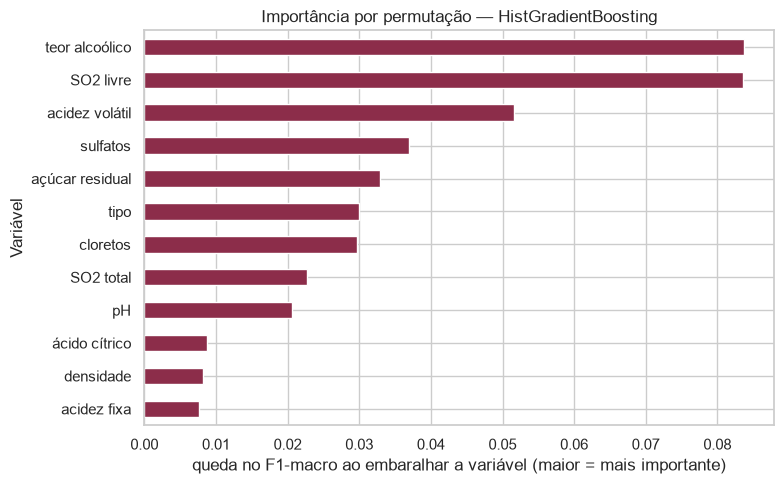

,queda no F1-macro
teor alcoólico,0.0837
SO2 livre,0.0836
acidez volátil,0.0516
sulfatos,0.0369
açúcar residual,0.0329
tipo,0.0299
cloretos,0.0297
SO2 total,0.0227
pH,0.0205
ácido cítrico,0.0088


In [27]:
imp = permutation_importance(melhor_clf, X_test, y_test_c, n_repeats=10, random_state=SEED,
                             scoring="f1_macro", n_jobs=-1)
imp_clf = pd.Series(imp.importances_mean, index=X_test.columns).rename(index=NOMES_PT).sort_values()
imp_clf.plot.barh(figsize=(8, 5), color="#8c2d4a",
                  title=f"Importância por permutação — {melhor_nome_clf}")
plt.xlabel("queda no F1-macro ao embaralhar a variável (maior = mais importante)")
plt.ylabel("Variável"); plt.tight_layout(); plt.show()
imp_clf.sort_values(ascending=False).round(4).to_frame("queda no F1-macro")

### 5.7 Discussão da classificação
**Resultado final no teste (esquema A):**

| Modelo | F1-macro | Acur. balanceada | Acurácia |
|---|---|---|---|
| **HistGradientBoosting** | **0,576** | 0,632 | 0,732 |
| Random Forest | 0,568 | 0,620 | 0,735 |
| SVM (RBF) | 0,557 | 0,653 | 0,694 |
| Regressão Logística | 0,455 | 0,646 | 0,538 |

O HistGradientBoosting e o Random Forest ficam **praticamente empatados** (0,576 contra 0,568), e a diferença está dentro da variação esperada, então não há um vencedor claro. A Regressão Logística é a pior em F1, pois a fronteira entre as faixas não é linear.

**Resultado por classe (HistGradientBoosting):**

| Classe | Precisão | Recall | F1 | Vinhos no teste |
|---|---|---|---|---|
| média | 0,883 | 0,758 | 0,816 | 823 |
| alta | 0,483 | 0,691 | 0,569 | 204 |
| baixa | 0,280 | 0,447 | 0,344 | 47 |

**Como ler a matriz de confusão.** Cada linha é a faixa **real** e cada coluna a faixa **prevista**; a diagonal são os acertos. Na versão normalizada, cada linha soma 100%.
- **Média:** 76% de acerto (624 de 823). Os erros vão para "alta" (18%) e "baixa" (6%).
- **Alta:** 69% de acerto (141 de 204), e 28% são confundidos com "média".
- **Baixa:** só 45% de acerto (21 de 47); 53% são classificados como "média".
- **Quase não há erros entre as pontas**: apenas 1 vinho "baixa" foi previsto como "alta" e 5 "altas" como "baixas". As confusões ocorrem entre **faixas vizinhas**, o que é coerente com uma escala sensorial contínua, em que um vinho de nota 4 e outro de nota 5 são quimicamente quase iguais.

**Por que a classe "baixa" é a mais difícil.** Ela tem poucos exemplos (≈ 4% dos dados) e é quimicamente parecida com a média. Por isso sua precisão é de apenas 0,28: de cada 100 vinhos previstos como "baixa", só 28 realmente são. Por nota original, os vinhos de nota 3 e 4 têm as piores taxas de acerto (33% e 46%).

**Variáveis decisivas (importância por permutação, HistGradientBoosting).** `teor alcoólico` e `SO2 livre` lideram, ambos com queda de ≈ 0,084 no F1-macro, seguidos por `acidez volátil` (≈ 0,051), `sulfatos` (≈ 0,037) e `açúcar residual` (≈ 0,033). `tipo` tem peso relevante aqui (≈ 0,030), diferente da regressão. Álcool e acidez volátil confirmam a EDA, e a importância do `SO2 livre` reforça a ideia de uma relação não linear.

**O que o GridSearch mudou.** Pouco em relação ao modelo com parâmetros padrão (no Random Forest da validação cruzada, de 0,560 para 0,567 de F1-macro). Para a classificação, o maior ganho veio de **tratar o desbalanceamento**, e não de ajustar hiperparâmetros.

## 6. Conclusões
### Resumo dos resultados

| Parte | Melhor modelo | Resultado no teste | Referência (baseline) |
|---|---|---|---|
| Regressão | Random Forest | RMSE **0,691** · MAE 0,532 · R² **0,382** | RMSE 0,881 · R² ≈ 0 |
| Classificação (3 faixas) | HistGradientBoosting | F1-macro **0,576** · acur. balanceada 0,632 | F1-macro 0,289 |

## Conclusões

1. **Os dados exigiram limpeza séria.** Vírgulas decimais perdidas, texto em colunas numéricas, valores impossíveis e 1.125 duplicadas foram corrigidos antes de modelar; sem isso, qualquer métrica seria inválida.
2. **Regressão:** os modelos superam claramente o baseline, e o Random Forest explica cerca de **38% da variação da nota**, errando em média ≈ 0,5 ponto. As previsões sofrem **regressão à média** (notas extremas são puxadas para 5–6), porque as pontas têm poucos exemplos e a nota é subjetiva.
3. **Classificação:** o F1-macro de ≈ 0,58 só é bom em comparação com o baseline (0,29). O maior ganho veio de **tratar o desbalanceamento**, e a **acurácia sozinha seria enganosa**. A classe "baixa" continua sendo a mais difícil de acertar.
4. **O que mais pesa na qualidade:** o **teor alcoólico** é a variável mais importante nas duas partes, seguido pela **acidez volátil** (efeito negativo) e pelo **SO2 livre** (efeito não linear).

## Limitações

- **Poucos exemplos das notas extremas** (3, 8 e 9), o que limita o aprendizado nas pontas da escala.
- **A nota é subjetiva** e as medidas químicas não captam aroma e sabor, por isso o R² tem um teto natural.
- A limpeza **reescala valores com base em faixas plausíveis**, uma suposição que não pudemos confirmar com o dado original.
- Resultados baseados em **uma única divisão treino/teste** (com semente fixa); a diferença entre os dois melhores classificadores está dentro da variação esperada.

## Próximos passos

Criar variáveis de interação (por exemplo, SO2 combinado = total − livre), treinar **modelos separados para tintos e brancos**, buscar mais amostras das classes raras e testar uma busca de hiperparâmetros mais ampla.